## Журнал исправлений

Исправлены только явные ошибки, в которых нет сомнений. Каждое место в ноутбуке помечено **⚠ ИСПРАВЛЕНИЕ №…**: что было, что стало и почему. Остальной текст и код не менялись.

| № | Где | Что исправлено | Меняет расчёт |
|---|---|---|---|
| 1 | Часть 1.2, текст | Тепловые эффекты стадий не сходились между собой и с кодом | нет (на k не влияет) |
| 2 | Часть 4.1, текст | 110.1 кДж/моль и 1.83 ГДж/т → 89.4 и 1.49, как считает код | нет |
| 3 | Часть 6, код `extended_coefficient_k`; тексты 6.3 и 9.2 | Двойной счёт пара и электричества: расширенный k 29.14 → 26.08 | **да** |
| 4 | Часть 8.2, текст | «газ TTF с 1960 года» → TTF только с апреля 2015 | нет (код не менялся) |

Ячейки частей 1–8 перезапущены. Ячейка с загрузкой файла Pink Sheet (путь `C:\Users\...`) не перезапускалась: её код и вывод исходные, исправления на неё не влияют.


# Расчетная модель коэффициента k и себестоимости карбамида

Этот ноутбук собирает всю математику и химию которые нужны чтобы обосновать коэффициент k и посчитать себестоимость карбамида на разных типах заводов.

Коэффициент k показывает сколько газа в единицах MMBtu уходит на производство одной тонны карбамида. Дальше в модели прогноза этот коэффициент связывает цену газа и себестоимость карбамида по формуле.

P_карбамид = k * P_газ + надбавка

Здесь P_карбамид это цена карбамида в долларах за тонну. P_газ это цена газа TTF в долларах за MMBtu. Надбавка это все остальное что накручивается рынком сверх физической себестоимости.

Структура ноутбука такая. Сначала химия реакций и термодинамика. Потом материальный баланс. Потом энергетический баланс. Потом расчет себестоимости по трем сценариям завода. Потом анализ чувствительности к цене газа. В конце проверка через регрессию на исторических данных.

## Часть 1. Химические реакции

### 1.1 Синтез аммиака

Аммиак получают из азота и водорода по реакции Габера и Боша.

N2 + 3H2 = 2NH3

Стандартный тепловой эффект равен -92.4 кДж на моль. Знак "-" означает что тепло выделяется при реакции. Такие реакции называют экзотермическими.

Стандартная энтальпия образования аммиака равна -46.2 кДж на моль. Азот и водород как простые вещества имеют энтальпию образования равную нулю. По закону Гесса тепловой эффект равен сумме энтальпий образования продуктов за вычетом суммы энтальпий образования исходных веществ.

### 1.2 Синтез карбамида

Карбамид получают из аммиака и диоксида углерода в две стадии.

Первая стадия это образование карбамата аммония. Тепловой эффект -125.6 кДж на моль. Тепло выделяется.

Вторая стадия это дегидратация карбамата. Тепловой эффект плюс 36.2 кДж на моль. Тепло поглощается, эту стадию нужно нагревать.

Суммарный тепловой эффект по разным источникам лежит в диапазоне от -89 до -133 кДж на моль. Разброс возникает потому что авторы по разному учитывают агрегатное состояние воды и карбамида. В коде ниже используется значение -89.4 кДж на моль (вода в виде пара).

> **⚠ ИСПРАВЛЕНИЕ №1.** Было: дегидратация «плюс 28.5 кДж на моль», для проекта «используется значение -110.1». Стало: плюс 36.2 и -89.4. Почему: старые числа не сходились ни между собой (-125.6 + 28.5 = -97.1, а не -110.1), ни с кодом. Код ниже по энтальпиям образования из своей же таблицы получает +36.2 для дегидратации и -89.4 для суммы и дальше использует именно -89.4 (`UREA_ENTHALPY_KJ_PER_MOL`). Текст приведён в соответствие с кодом. Сами справочные энтальпии не проверялись и не менялись. На коэффициент k эти числа не влияют.

### 1.3 Типы данных

Важно различать два типа данных. Первый тип это табличные величины которые берутся из справочников и не зависят от завода. Это молярные массы, энтальпии образования, физические константы перевода единиц. Второй тип это отраслевые параметры которые зависят от технологии и возраста завода. Это расход газа на аммиак, расход аммиака на карбамид, расход пара и электричества. Для первого типа источник это справочник Atkins Physical Chemistry и база Active Thermochemical Tables. Для второго типа источники указаны отдельно по каждому параметру.

In [2]:
from typing import Dict, List, Tuple


MOLAR_MASSES: Dict[str, float] = {
    "N2": 28.013,
    "H2": 2.016,
    "NH3": 17.031,
    "CO2": 44.009,
    "urea": 60.056,
    "H2O": 18.015
}

ENTHALPIES_OF_FORMATION: Dict[str, float] = {
    "NH3_gas": -46.2,
    "CO2_gas": -393.5,
    "H2O_liquid": -285.8,
    "H2O_gas": -241.8,
    "urea_solid": -333.5,
    "carbamate_solid": -611.5,
    "N2_gas": 0.0,
    "H2_gas": 0.0
}


def calculate_reaction_enthalpy(
    products: Dict[str, float],
    reactants: Dict[str, float]
) -> float:
    """
    Считает тепловой эффект реакции по закону Гесса.

    Закон Гесса гласит что тепловой эффект реакции зависит только
    от начального и конечного состояния системы но не от того
    через какие промежуточные стадии идет процесс.

    Параметры
    products : словарь где ключ это название вещества а значение
        это произведение стехиометрического коэффициента на
        стандартную энтальпию образования.
    reactants : такой же словарь для исходных веществ.

    Возвращает
    Тепловой эффект реакции в кДж на моль.
    """
    sum_products = sum(products.values())
    sum_reactants = sum(reactants.values())
    return sum_products - sum_reactants


def ammonia_synthesis_enthalpy() -> float:
    """
    Возвращает тепловой эффект реакции синтеза аммиака.

    Реакция N2 плюс 3H2 равно 2NH3. Азот и водород как простые
    вещества имеют нулевую энтальпию образования. Продукт это
    две молекулы аммиака.

    Возвращает
    Тепловой эффект в кДж на моль. Значение отрицательное потому
    что реакция экзотермическая.
    """
    products = {"NH3": 2 * ENTHALPIES_OF_FORMATION["NH3_gas"]}
    reactants = {
        "N2": 1 * ENTHALPIES_OF_FORMATION["N2_gas"],
        "H2": 3 * ENTHALPIES_OF_FORMATION["H2_gas"]
    }
    return calculate_reaction_enthalpy(products, reactants)


def carbamate_formation_enthalpy() -> float:
    """
    Возвращает тепловой эффект первой стадии синтеза карбамида.

    Реакция 2NH3 плюс CO2 равно NH2COONH4. Это образование карбамата
    аммония. Тепловой эффект считается по закону Гесса через
    энтальпии образования всех участников реакции.

    Возвращает
    Тепловой эффект в кДж на моль. Значение отрицательное потому
    что тепло выделяется.
    """
    products = {
        "carbamate": 1 * ENTHALPIES_OF_FORMATION["carbamate_solid"]
    }
    reactants = {
        "NH3": 2 * ENTHALPIES_OF_FORMATION["NH3_gas"],
        "CO2": 1 * ENTHALPIES_OF_FORMATION["CO2_gas"]
    }
    return calculate_reaction_enthalpy(products, reactants)


def carbamate_dehydration_enthalpy() -> float:
    """
    Возвращает тепловой эффект второй стадии синтеза карбамида.

    Реакция NH2COONH4 равно CO(NH2)2 плюс H2O. Это дегидратация
    карбамата с образованием карбамида и воды. Тепловой эффект
    считается по закону Гесса через энтальпии образования всех
    участников реакции. Вода рассматривается в газовой фазе
    потому что в реакторе она уходит именно паром.

    Возвращает
    Тепловой эффект в кДж на моль. Значение положительное потому
    что тепло поглощается.
    """
    products = {
        "urea": 1 * ENTHALPIES_OF_FORMATION["urea_solid"],
        "H2O": 1 * ENTHALPIES_OF_FORMATION["H2O_gas"]
    }
    reactants = {
        "carbamate": 1 * ENTHALPIES_OF_FORMATION["carbamate_solid"]
    }
    return calculate_reaction_enthalpy(products, reactants)


def urea_total_enthalpy_from_stages() -> float:
    """
    Считает суммарный тепловой эффект синтеза карбамида как сумму
    двух стадий.

    Первая стадия выделяет тепло, вторая поглощает. Суммарный
    эффект получается сложением двух значений.

    Возвращает
    Суммарный тепловой эффект в кДж на моль.
    """
    return carbamate_formation_enthalpy() + carbamate_dehydration_enthalpy()


def urea_total_enthalpy_from_formation() -> float:
    """
    Считает суммарный тепловой эффект синтеза карбамида через
    энтальпии образования.

    Суммарная реакция 2NH3 плюс CO2 равно CO(NH2)2 плюс H2O.
    Вода рассматривается в газовой фазе, карбамид в твердой.

    Возвращает
    Тепловой эффект в кДж на моль.
    """
    products = {
        "urea": 1 * ENTHALPIES_OF_FORMATION["urea_solid"],
        "H2O": 1 * ENTHALPIES_OF_FORMATION["H2O_gas"]
    }
    reactants = {
        "NH3": 2 * ENTHALPIES_OF_FORMATION["NH3_gas"],
        "CO2": 1 * ENTHALPIES_OF_FORMATION["CO2_gas"]
    }
    return calculate_reaction_enthalpy(products, reactants)


print("Энтальпия синтеза аммиака кДж на моль:", round(ammonia_synthesis_enthalpy(), 2))
print("Энтальпия карбамата кДж на моль:", carbamate_formation_enthalpy())
print("Энтальпия дегидратации кДж на моль:", carbamate_dehydration_enthalpy())
print("Сумма стадий кДж на моль:", urea_total_enthalpy_from_stages())
print("Через энтальпии образования кДж на моль:", round(urea_total_enthalpy_from_formation(), 2))

Энтальпия синтеза аммиака кДж на моль: -92.4
Энтальпия карбамата кДж на моль: -125.60000000000002
Энтальпия дегидратации кДж на моль: 36.200000000000045
Сумма стадий кДж на моль: -89.39999999999998
Через энтальпии образования кДж на моль: -89.4


## Часть 2. Материальный баланс

### 2.1 Стехиометрия

Из суммарной реакции видно что на одну молекулу карбамида нужно две молекулы аммиака и одна молекула диоксида углерода. Побочно образуется одна молекула воды.

### 2.2 Почему аммиака меньше тонны

Аммиак это только часть молекулы карбамида. Остальная часть это диоксид углерода. Если сложить массы аммиака и CO2 которые вошли в реакцию то получится 1.3 тонны. На выходе получается тонна карбамида и 0.3 тонны воды. Масса сохраняется полностью.

### 2.3 Практический расход

Теоретический минимум расхода аммиака равен 0.567 тонны на тонну карбамида. На реальном заводе расход чуть выше из за потерь в цикле синтеза. В калькуляторе себестоимости Yara используется значение 0.58. Эта же цифра подтверждается в отраслевых обзорах Market Realist.

In [3]:
def stoichiometric_coefficient_ammonia() -> float:
    """
    Считает теоретический расход аммиака на тонну карбамида.

    По суммарной реакции на одну молекулу карбамида нужно две
    молекулы аммиака. Коэффициент равен двум молярным массам
    аммиака деленным на молярную массу карбамида.

    Возвращает
    Расход аммиака в тоннах на тонну карбамида.
    """
    return 2 * MOLAR_MASSES["NH3"] / MOLAR_MASSES["urea"]


def stoichiometric_coefficient_co2() -> float:
    """
    Считает теоретический расход диоксида углерода на тонну.

    По суммарной реакции на одну молекулу карбамида нужна одна
    молекула диоксида углерода.

    Возвращает
    Расход CO2 в тоннах на тонну карбамида.
    """
    return MOLAR_MASSES["CO2"] / MOLAR_MASSES["urea"]


def stoichiometric_coefficient_water() -> float:
    """
    Считает теоретический выход воды на тонну карбамида.

    По суммарной реакции на одну молекулу карбамида образуется
    одна молекула воды.

    Возвращает
    Выход воды в тоннах на тонну карбамида.
    """
    return MOLAR_MASSES["H2O"] / MOLAR_MASSES["urea"]


def practical_ammonia_coefficient() -> float:
    """
    Возвращает практический расход аммиака на тонну карбамида.

    Теоретический минимум равен примерно 0.567. На реальном
    заводе расход выше из за потерь в цикле синтеза. Значение
    0.58 приводится в калькуляторе себестоимости компании
    Yara International.

    Возвращает
    Практический расход аммиака в тоннах на тонну карбамида.
    """
    return 0.58


def material_balance_full(urea_mass_kg: float = 1000.0) -> Dict[str, float]:
    """
    Считает полный материальный баланс реакции синтеза карбамида.

    Возвращает все массы участвующих веществ и суммы по обеим
    сторонам реакции. По закону сохранения массы суммы должны
    совпадать.

    Параметры
    urea_mass_kg : масса карбамида в килограммах. По умолчанию
        берется одна тонна.

    Возвращает
    Словарь со всеми массами и суммами.
    """
    r_nh3 = stoichiometric_coefficient_ammonia()
    r_co2 = stoichiometric_coefficient_co2()
    r_h2o = stoichiometric_coefficient_water()
    ammonia_in = r_nh3 * urea_mass_kg
    co2_in = r_co2 * urea_mass_kg
    water_out = r_h2o * urea_mass_kg
    return {
        "ammonia_in_kg": ammonia_in,
        "co2_in_kg": co2_in,
        "urea_out_kg": urea_mass_kg,
        "water_out_kg": water_out,
        "total_in_kg": ammonia_in + co2_in,
        "total_out_kg": urea_mass_kg + water_out
    }


print("Стехиометрический расход аммиака т на т:", round(stoichiometric_coefficient_ammonia(), 4))
print("Стехиометрический расход CO2 т на т:", round(stoichiometric_coefficient_co2(), 4))
print("Стехиометрический выход воды т на т:", round(stoichiometric_coefficient_water(), 4))
print("Практический расход аммиака т на т:", practical_ammonia_coefficient())
print()
balance = material_balance_full()
print("Материальный баланс в килограммах:")
for key, value in balance.items():
    print(" ", key, round(value, 2))

Стехиометрический расход аммиака т на т: 0.5672
Стехиометрический расход CO2 т на т: 0.7328
Стехиометрический выход воды т на т: 0.3
Практический расход аммиака т на т: 0.58

Материальный баланс в килограммах:
  ammonia_in_kg 567.17
  co2_in_kg 732.8
  urea_out_kg 1000.0
  water_out_kg 299.97
  total_in_kg 1299.97
  total_out_kg 1299.97


## Часть 3. Коэффициент k

### 3.1 Компоненты коэффициента

Коэффициент k складывается из двух частей. Первая это газ ушедший на производство аммиака который нужен для одной тонны карбамида. Вторая это технологический газ на самой стадии превращения аммиака в карбамид.

Для первой части нужны два числа. Расход газа на тонну аммиака и расход аммиака на тонну карбамида.

Расход газа на аммиак для среднего завода равен 36 MMBtu на тонну. Источник это калькулятор себестоимости Yara International со ссылкой на консалтинговую компанию Blue Johnson and Associates.

Расход аммиака равен 0.58 тонны на тонну карбамида. Источник тот же, калькулятор Yara.

Для второй части нужно значение технологического газа. Оно равно 5.2 MMBtu на тонну карбамида. Источник тоже калькулятор Yara, подтверждено публикацией Market Realist.

### 3.2 Формула

k равно газ на аммиак умножить на расход аммиака плюс технологический газ.

36 умножить на 0.58 равно 20.88. Плюс 5.2 равно 26.08 MMBtu на тонну карбамида.

In [4]:
GAS_PER_AMMONIA_MMBTU_DEFAULT: float = 36.0
AMMONIA_PER_UREA_DEFAULT: float = 0.58
PROCESS_GAS_PER_UREA_MMBTU: float = 5.2


def gas_cost_coefficient(
    gas_per_ammonia: float = GAS_PER_AMMONIA_MMBTU_DEFAULT,
    ammonia_per_urea: float = AMMONIA_PER_UREA_DEFAULT,
    process_gas: float = PROCESS_GAS_PER_UREA_MMBTU
) -> float:
    """
    Считает сквозной коэффициент k расхода газа на тонну карбамида.

    Логика расчета. Сначала газ умножается на расход аммиака на
    тонну карбамида. Получается газ ушедший на производство
    аммиака который нужен для одной тонны карбамида. Потом
    прибавляется технологический газ на стадии карбамида.

    Параметры
    gas_per_ammonia : расход газа на тонну аммиака в MMBtu.
        Значение по умолчанию 36 из калькулятора Yara International.
    ammonia_per_urea : расход аммиака на тонну карбамида в тоннах.
        Значение по умолчанию 0.58 из калькулятора Yara.
    process_gas : технологический газ на стадии карбамида в MMBtu
        на тонну. Значение по умолчанию 5.2 из калькулятора Yara.

    Возвращает
    Коэффициент k в MMBtu на тонну карбамида.
    """
    gas_on_ammonia = gas_per_ammonia * ammonia_per_urea
    return gas_on_ammonia + process_gas


def gas_cost_breakdown(
    gas_per_ammonia: float = GAS_PER_AMMONIA_MMBTU_DEFAULT,
    ammonia_per_urea: float = AMMONIA_PER_UREA_DEFAULT,
    process_gas: float = PROCESS_GAS_PER_UREA_MMBTU
) -> Dict[str, float]:
    """
    Возвращает разложение коэффициента k на две составляющие.

    Параметры такие же как у gas_cost_coefficient.

    Возвращает
    Словарь с газом на аммиак, технологическим газом и суммой.
    """
    gas_on_ammonia = gas_per_ammonia * ammonia_per_urea
    return {
        "gas_on_ammonia_mmbtu": gas_on_ammonia,
        "process_gas_mmbtu": process_gas,
        "k_mmbtu": gas_on_ammonia + process_gas
    }


breakdown = gas_cost_breakdown()
for key, value in breakdown.items():
    print(key, round(value, 2))

gas_on_ammonia_mmbtu 20.88
process_gas_mmbtu 5.2
k_mmbtu 26.08


## Часть 4. Энергетический баланс

### 4.1 Тепловой эффект реакций в пересчете на тонну

Стандартные энтальпии даны в кДж на моль. Чтобы перейти к тоннам нужно поделить на молярную массу и умножить на тысячу. Например для аммиака берем 46.2 кДж на моль делим на 17.031 грамма на моль и получаем 2.71 МДж на килограмм или 2.71 ГДж на тонну.

Аналогично для карбамида. Берем 89.4 кДж на моль делим на 60.056 грамма на моль и получаем 1.49 ГДж на тонну.

> **⚠ ИСПРАВЛЕНИЕ №2.** Было: «110.1 кДж на моль … 1.83 ГДж на тонну». Стало: 89.4 и 1.49. Почему: код ниже (`urea_heat_per_ton`) берёт -89.4 кДж/моль и печатает 1.489 ГДж/т, текст с ним расходился (см. исправление №1).

### 4.2 Расход пара на стадии карбамида

Современные энергоэффективные заводы потребляют от 0.4 до 0.6 Гкал пара на тонну карбамида. Пар нужен для нагрева реактора и упаривания воды. Источник это обзор технологий производства карбамида. Для расчета берется верхняя граница 0.6 Гкал чтобы оценка была консервативной. В гигаджоулях это 0.6 умножить на 4.184 и получается 2.51 ГДж на тонну.

### 4.3 Расход электроэнергии

Современные заводы потребляют от 50 до 120 кВт ч электроэнергии на тонну карбамида. Источник это научная статья ASME 2014 года. Для расчета берется середина 80 кВт ч.

Электроэнергия это полезная энергия. Чтобы получить первичную энергию газа нужно учесть КПД электростанции. Для современной газопоршневой установки КПД около 40 процентов.

Расчет такой. 80 умножить на 0.0036 и поделить на 0.4. Произведение дает 0.288 ГДж полезной энергии. Деление на 0.4 дает 0.72 ГДж первичной энергии газа на тонну карбамида.

In [5]:
UREA_ENTHALPY_KJ_PER_MOL: float = urea_total_enthalpy_from_stages()
STEAM_GCAL_PER_TON: float = 0.6
ELECTRICITY_KWH_PER_TON: float = 80.0
GCAL_TO_GJ: float = 4.184
KWH_TO_GJ: float = 0.0036
GAS_POWER_PLANT_EFFICIENCY: float = 0.4


def reaction_heat_per_ton(
    enthalpy_kj_per_mol: float,
    molar_mass_g_per_mol: float
) -> float:
    """
    Переводит тепловой эффект реакции из кДж на моль в ГДж на тонну.

    Логика такая. Делим энтальпию на молярную массу и получаем
    кДж на грамм. Умножаем на тысячу и получаем кДж на килограмм.
    Умножаем еще на тысячу и получаем кДж на тонну. Делим на
    миллион и получаем ГДж на тонну.

    Параметры
    enthalpy_kj_per_mol : тепловой эффект реакции в кДж на моль.
    molar_mass_g_per_mol : молярная масса продукта в г на моль.

    Возвращает
    Тепловой эффект в ГДж на тонну продукта.
    """
    kj_per_kg = abs(enthalpy_kj_per_mol) / molar_mass_g_per_mol * 1000
    gj_per_ton = kj_per_kg * 1000 / 1_000_000
    return gj_per_ton


def ammonia_heat_per_ton() -> float:
    """
    Возвращает тепловой эффект синтеза аммиака в ГДж на тонну.

    Использует тепловой эффект реакции и молярную массу аммиака.

    Возвращает
    Тепловой эффект в ГДж на тонну аммиака.
    """
    return reaction_heat_per_ton(
        ammonia_synthesis_enthalpy() / 2,
        MOLAR_MASSES["NH3"]
    )


def urea_heat_per_ton() -> float:
    """
    Возвращает суммарный тепловой эффект синтеза карбамида в ГДж
    на тонну.

    Возвращает
    Тепловой эффект в ГДж на тонну карбамида.
    """
    return reaction_heat_per_ton(
        UREA_ENTHALPY_KJ_PER_MOL,
        MOLAR_MASSES["urea"]
    )


def steam_energy_per_ton() -> float:
    """
    Возвращает энергию пара на тонну карбамида в ГДж.

    Источник это обзор технологий производства карбамида.
    Значение 0.6 Гкал на тонну взято как верхняя граница
    диапазона 0.4 и 0.6 для консервативности.

    Возвращает
    Энергию пара в ГДж на тонну карбамида.
    """
    return STEAM_GCAL_PER_TON * GCAL_TO_GJ


def electricity_useful_per_ton() -> float:
    """
    Возвращает полезную электроэнергию на тонну карбамида в ГДж.

    Источник это ASME 2014. Значение 80 кВт ч это середина
    диапазона 50 и 120.

    Возвращает
    Полезную электроэнергию в ГДж на тонну карбамида.
    """
    return ELECTRICITY_KWH_PER_TON * KWH_TO_GJ


def electricity_primary_energy_per_ton() -> float:
    """
    Возвращает первичную энергию газа для производства нужной
    электроэнергии.

    Полезная энергия делится на КПД газовой электростанции.
    КПД принят 0.4 что соответствует современным газопоршневым
    установкам.

    Возвращает
    Первичную энергию газа в ГДж на тонну карбамида.
    """
    return electricity_useful_per_ton() / GAS_POWER_PLANT_EFFICIENCY


print("Тепло аммиака ГДж на т:", round(ammonia_heat_per_ton(), 3))
print("Тепло карбамида ГДж на т:", round(urea_heat_per_ton(), 3))
print("Энергия пара ГДж на т:", round(steam_energy_per_ton(), 3))
print("Полезная электроэнергия ГДж на т:", round(electricity_useful_per_ton(), 3))
print("Первичная энергия газа на электричество ГДж на т:", round(electricity_primary_energy_per_ton(), 3))

Тепло аммиака ГДж на т: 2.713
Тепло карбамида ГДж на т: 1.489
Энергия пара ГДж на т: 2.51
Полезная электроэнергия ГДж на т: 0.288
Первичная энергия газа на электричество ГДж на т: 0.72


## Часть 5. Три сценария завода

### 5.1 Зачем нужны сценарии

Одна фиксированная цифра k не описывает всю отрасль. Разные заводы потребляют разное количество газа в зависимости от технологии и возраста. Поэтому в проекте задаются три сценария которые охватывают диапазон реальных заводов.

### 5.2 Эффективный завод

Современные агрегаты потребляют около 28 MMBtu на тонну аммиака. Ориентир это агрегат Аммиак 4 компании Акрон запущенный в 2020 году. Он потребляет около 938 кубометров газа на тонну аммиака что близко к 28 MMBtu. Другой ориентир это цели модернизации индонезийской компании Pupuk Indonesia.

### 5.3 Средний завод

Среднемировой уровень это 36 MMBtu на тонну аммиака. Именно эту цифру использует Yara International в своем калькуляторе.

### 5.4 Устаревший завод

Старые агрегаты потребляют от 38 до 41 MMBtu на тонну аммиака. Это характерно для российских агрегатов АМ 70, АМ 76 и ТЕС которые были введены в строй с 1973 по 1988 год. Их энергопотребление составляет от 8 до 9 Гкал на тонну аммиака. Для расчета берется 40 MMBtu.

In [6]:
def build_plant_scenarios() -> List[Dict[str, float]]:
    """
    Собирает три сценария завода с разной эффективностью.

    Для каждого сценария считается коэффициент k по общей
    формуле с соответствующим расходом газа на аммиак.

    Возвращает
    Список словарей с названием сценария, расходом газа на
    аммиак и итоговым коэффициентом k.
    """
    scenarios = [
        {
            "name": "Эффективный",
            "gas_per_ammonia_mmbtu": 28.0,
            "source": "Акрон Аммиак 4 и Pupuk Indonesia"
        },
        {
            "name": "Средний",
            "gas_per_ammonia_mmbtu": 36.0,
            "source": "Yara International и Blue Johnson"
        },
        {
            "name": "Устаревший",
            "gas_per_ammonia_mmbtu": 40.0,
            "source": "Российские агрегаты АМ 70 и АМ 76"
        }
    ]
    for scenario in scenarios:
        scenario["k_mmbtu"] = gas_cost_coefficient(
            gas_per_ammonia=scenario["gas_per_ammonia_mmbtu"]
        )
    return scenarios


def print_scenarios(scenarios: List[Dict[str, float]]) -> None:
    """
    Печатает таблицу сценариев завода.

    Параметры
    scenarios : список словарей полученный из build_plant_scenarios.

    Возвращает
    Ничего, только печатает таблицу.
    """
    for scenario in scenarios:
        print(
            scenario["name"],
            "газ на аммиак",
            scenario["gas_per_ammonia_mmbtu"],
            "MMBtu на т, k",
            round(scenario["k_mmbtu"], 2),
            "MMBtu на т карбамида"
        )


scenarios = build_plant_scenarios()
print_scenarios(scenarios)

Эффективный газ на аммиак 28.0 MMBtu на т, k 21.44 MMBtu на т карбамида
Средний газ на аммиак 36.0 MMBtu на т, k 26.08 MMBtu на т карбамида
Устаревший газ на аммиак 40.0 MMBtu на т, k 28.4 MMBtu на т карбамида


## Часть 6. Расчет себестоимости

### 6.1 Структура себестоимости

Себестоимость одной тонны карбамида складывается из нескольких статей. Основная это газ в виде сырья. Дополнительные это пар и электричество которые тоже зависят от цены газа. Кроме того есть аммиак как отдельная статья если завод покупает его на стороне а не производит сам.

### 6.2 Формула полной себестоимости

Полная себестоимость равна произведению коэффициента k на цену газа плюс стоимость пара плюс стоимость электричества плюс стоимость аммиака если он покупается.

Цена пара и цена электричества тоже зависят от цены газа. Пар в Европе производится из газа. Электричество тоже. Поэтому при росте цены газа растет вся себестоимость а не только сырьевая часть.

### 6.3 Упрощенный подход

Для проекта используется упрощение. Пар и электричество переводятся в газовый эквивалент и прибавляются к коэффициенту k. Тогда полная себестоимость считается как произведение расширенного коэффициента на цену газа. Это упрощает формулу для модели прогноза.

> **⚠ ИСПРАВЛЕНИЕ №3.** Было: пар и электричество прибавляются к k (расширенный k = 29.14). Стало: не прибавляются, расширенный k = базовому k = 26.08. Почему: в базовом k уже есть 5.2 MMBtu технологического газа на стадии карбамида. Газ на этой стадии не сырьё, значит эти 5.2 и есть энергия на пар и электричество, и прибавлять их ещё раз — двойной счёт. Подробности — в комментарии в коде ниже.

In [7]:
def steam_gas_equivalent_mmbtu() -> float:
    """
    Переводит энергию пара в газовый эквивалент в MMBtu.

    Энергия пара равна 2.51 ГДж на тонну. Один MMBtu равен
    1.055 ГДж. Значит газовый эквивалент равен 2.51 поделить
    на 1.055.

    Возвращает
    Газовый эквивалент пара в MMBtu на тонну карбамида.
    """
    return steam_energy_per_ton() / 1.055


def electricity_gas_equivalent_mmbtu() -> float:
    """
    Переводит первичную энергию газа для электричества в MMBtu.

    Первичная энергия равна 0.72 ГДж на тонну. Делим на 1.055
    и получаем газовый эквивалент в MMBtu.

    Возвращает
    Газовый эквивалент электричества в MMBtu на тонну.
    """
    return electricity_primary_energy_per_ton() / 1.055


def extended_coefficient_k(
    gas_per_ammonia: float = GAS_PER_AMMONIA_MMBTU_DEFAULT
) -> float:
    """
    Считает расширенный коэффициент k включая пар и электричество.

    После ИСПРАВЛЕНИЯ №3 совпадает с базовым коэффициентом:
    пар и электричество стадии карбамида уже входят в 5.2 MMBtu.
    (Было: к базовому коэффициенту прибавлялись газовые
    эквиваленты пара и электричества.)

    Параметры
    gas_per_ammonia : расход газа на тонну аммиака в MMBtu.

    Возвращает
    Расширенный коэффициент в MMBtu на тонну карбамида.
    """
    base = gas_cost_coefficient(gas_per_ammonia=gas_per_ammonia)
    # ⚠ ИСПРАВЛЕНИЕ №3. Двойной счёт пара и электричества.
    # Было:   return base + steam_gas_equivalent_mmbtu() + electricity_gas_equivalent_mmbtu()
    #         base = 20.88 (газ на аммиак) + 5.2 (технологический газ стадии карбамида) = 26.08,
    #         итог 26.08 + 2.38 + 0.68 = 29.14 MMBtu/т.
    # Стало:  return base   (26.08 MMBtu/т).
    # Почему: на стадии карбамида газ не сырьё: CO2 приходит с аммиачного производства.
    #         Значит 5.2 MMBtu «технологического газа» в base — это и есть энергия
    #         стадии карбамида, то есть пар и электричество. Прибавлять к base пар
    #         и электричество ещё раз — считать одну и ту же энергию дважды.
    #         Пар + электричество, посчитанные снизу (2.38 + 0.68 = 3.06 MMBtu), — независимая
    #         оценка тех же 5.2. Её печатаем ниже для сравнения, но не прибавляем.
    return base


def urea_production_cost(
    gas_price_usd_per_mmbtu: float,
    gas_per_ammonia: float = GAS_PER_AMMONIA_MMBTU_DEFAULT,
    include_energy: bool = True
) -> Dict[str, float]:
    """
    Считает себестоимость одной тонны карбамида по цене газа.

    Параметры
    gas_price_usd_per_mmbtu : цена газа в долларах за MMBtu.
    gas_per_ammonia : расход газа на тонну аммиака в MMBtu.
    include_energy : нужно ли включать пар и электричество
        в расчет себестоимости.

    Возвращает
    Словарь с базовой себестоимостью, полной себестоимостью и
    использованными коэффициентами.
    """
    base_k = gas_cost_coefficient(gas_per_ammonia=gas_per_ammonia)
    base_cost = base_k * gas_price_usd_per_mmbtu
    # После ИСПРАВЛЕНИЯ №3 full_k = base_k, поэтому energy_premium_usd_per_ton = 0.
    if include_energy:
        full_k = extended_coefficient_k(gas_per_ammonia=gas_per_ammonia)
        full_cost = full_k * gas_price_usd_per_mmbtu
    else:
        full_k = base_k
        full_cost = base_cost
    return {
        "gas_price_usd_per_mmbtu": gas_price_usd_per_mmbtu,
        "base_k_mmbtu": base_k,
        "full_k_mmbtu": full_k,
        "base_cost_usd_per_ton": base_cost,
        "full_cost_usd_per_ton": full_cost,
        "energy_premium_usd_per_ton": full_cost - base_cost
    }


def markup_from_price(
    urea_price_usd_per_ton: float,
    gas_price_usd_per_mmbtu: float,
    gas_per_ammonia: float = GAS_PER_AMMONIA_MMBTU_DEFAULT
) -> Dict[str, float]:
    """
    Считает рыночную надбавку карбамида над газовой себестоимостью.

    Надбавка это то что остается от цены после вычитания
    физической себестоимости газа. Именно эту величину
    прогнозирует модель.

    Параметры
    urea_price_usd_per_ton : цена карбамида в долларах за тонну.
    gas_price_usd_per_mmbtu : цена газа TTF в долларах за MMBtu.
    gas_per_ammonia : расход газа на тонну аммиака в MMBtu.

    Возвращает
    Словарь с себестоимостью и надбавкой.
    """
    k = gas_cost_coefficient(gas_per_ammonia=gas_per_ammonia)
    cost = k * gas_price_usd_per_mmbtu
    return {
        "k_mmbtu": k,
        "cost_usd_per_ton": cost,
        "markup_usd_per_ton": urea_price_usd_per_ton - cost
    }


gas_equiv_steam = steam_gas_equivalent_mmbtu()
gas_equiv_elec = electricity_gas_equivalent_mmbtu()
print("Газовый эквивалент пара MMBtu на т:", round(gas_equiv_steam, 3))
print("Газовый эквивалент электричества MMBtu на т:", round(gas_equiv_elec, 3))
print("Расширенный коэффициент k MMBtu на т:", round(extended_coefficient_k(), 2))
# ⚠ ИСПРАВЛЕНИЕ №3: добавлена строка для сравнения с 5.2 MMBtu, на расчёт не влияет.
print("Пар + электричество снизу вверх MMBtu на т:", round(gas_equiv_steam + gas_equiv_elec, 2),
      "(сравнить с 5.2 в калькуляторе Yara)")
print()
cost_example = urea_production_cost(gas_price_usd_per_mmbtu=10.0)
for key, value in cost_example.items():
    print(key, round(value, 2))

Газовый эквивалент пара MMBtu на т: 2.38
Газовый эквивалент электричества MMBtu на т: 0.682
Расширенный коэффициент k MMBtu на т: 26.08
Пар + электричество снизу вверх MMBtu на т: 3.06 (сравнить с 5.2 в калькуляторе Yara)

gas_price_usd_per_mmbtu 10.0
base_k_mmbtu 26.08
full_k_mmbtu 26.08
base_cost_usd_per_ton 260.8
full_cost_usd_per_ton 260.8
energy_premium_usd_per_ton 0.0


## Часть 7. Сравнение сценариев при разных ценах газа

### 7.1 Зачем это нужно

Когда цена газа растет, себестоимость карбамида растет по разному на разных заводах. На эффективном заводе газа уходит меньше поэтому рост слабее. На устаревшем заводе газа уходит больше поэтому рост сильнее. Это ключевой результат для экономической интерпретации.

### 7.2 Что считается

Для каждой цены газа от 5 до 25 долларов за MMBtu считается себестоимость по трем сценариям. Строится таблица где видно как расходятся себестоимости. Разница между устаревшим и эффективным заводом называется технологическим спредом.

In [8]:
def scenario_cost_table(
    gas_prices: List[float]
) -> List[Dict[str, float]]:
    """
    Считает себестоимость карбамида для трех сценариев завода
    при разных ценах газа.

    Параметры
    gas_prices : список цен газа в долларах за MMBtu.

    Возвращает
    Список словарей где для каждой цены газа указана
    себестоимость по трем сценариям и технологический спред.
    """
    scenarios = build_plant_scenarios()
    rows: List[Dict[str, float]] = []
    for price in gas_prices:
        row: Dict[str, float] = {"gas_price": price}
        costs = {}
        for scenario in scenarios:
            k = scenario["k_mmbtu"]
            costs[scenario["name"]] = k * price
            row[scenario["name"]] = round(k * price, 2)
        row["spread"] = round(
            costs["Устаревший"] - costs["Эффективный"], 2
        )
        rows.append(row)
    return rows


def sensitivity_to_gas_growth(
    base_gas_price: float,
    growth_percent: float
) -> List[Dict[str, float]]:
    """
    Считает как меняется себестоимость при росте цены газа.

    Параметры
    base_gas_price : базовая цена газа в долларах за MMBtu.
    growth_percent : рост цены газа в процентах.

    Возвращает
    Список словарей со старой и новой себестоимостью по каждому
    сценарию завода.
    """
    scenarios = build_plant_scenarios()
    new_price = base_gas_price * (1 + growth_percent / 100)
    result: List[Dict[str, float]] = []
    for scenario in scenarios:
        k = scenario["k_mmbtu"]
        old_cost = k * base_gas_price
        new_cost = k * new_price
        result.append({
            "name": scenario["name"],
            "k_mmbtu": k,
            "old_cost": round(old_cost, 2),
            "new_cost": round(new_cost, 2),
            "delta_cost": round(new_cost - old_cost, 2),
            "delta_percent": round(
                (new_cost - old_cost) / old_cost * 100, 2
            )
        })
    return result


prices = [5.0, 10.0, 15.0, 20.0, 25.0]
print("Сравнение сценариев при разных ценах газа:")
for row in scenario_cost_table(prices):
    print(row)
print()
print("Рост цены газа с 10 до плюс 30 процентов:")
for row in sensitivity_to_gas_growth(base_gas_price=10.0, growth_percent=30.0):
    print(row)

Сравнение сценариев при разных ценах газа:
{'gas_price': 5.0, 'Эффективный': 107.2, 'Средний': 130.4, 'Устаревший': 142.0, 'spread': 34.8}
{'gas_price': 10.0, 'Эффективный': 214.4, 'Средний': 260.8, 'Устаревший': 284.0, 'spread': 69.6}
{'gas_price': 15.0, 'Эффективный': 321.6, 'Средний': 391.2, 'Устаревший': 426.0, 'spread': 104.4}
{'gas_price': 20.0, 'Эффективный': 428.8, 'Средний': 521.6, 'Устаревший': 568.0, 'spread': 139.2}
{'gas_price': 25.0, 'Эффективный': 536.0, 'Средний': 652.0, 'Устаревший': 710.0, 'spread': 174.0}

Рост цены газа с 10 до плюс 30 процентов:
{'name': 'Эффективный', 'k_mmbtu': 21.439999999999998, 'old_cost': 214.4, 'new_cost': 278.72, 'delta_cost': 64.32, 'delta_percent': 30.0}
{'name': 'Средний', 'k_mmbtu': 26.08, 'old_cost': 260.8, 'new_cost': 339.04, 'delta_cost': 78.24, 'delta_percent': 30.0}
{'name': 'Устаревший', 'k_mmbtu': 28.4, 'old_cost': 284.0, 'new_cost': 369.2, 'delta_cost': 85.2, 'delta_percent': 30.0}


## Часть 8. Проверка коэффициента через регрессию

### 8.1 Зачем нужна проверка

Все расчеты в частях с первой по седьмую дают теоретическую себестоимость. Но рынок может работать иначе. Поэтому коэффициент k нужно проверить на исторических данных. Для этого строится линейная регрессия цены карбамида на цену газа. Если коэффициент при цене газа близок к 26 MMBtu значит физическая себестоимость объясняет цену. Если сильно отличается значит рынок работает иначе и нужно разбираться отдельно.

### 8.2 Данные для регрессии

Данные берутся из World Bank Pink Sheet. Это месячные цены на карбамид и газ Европы (колонка «Natural gas, Europe») с 1960 года по настоящее время. Ценой TTF эта колонка стала только с апреля 2015 года.

> **⚠ ИСПРАВЛЕНИЕ №4.** Было: «цены на карбамид и газ TTF за период с 1960 года». Стало: газ Европы, TTF — только с апреля 2015. Почему: до апреля 2015 World Bank давал в этой колонке среднюю цену импорта газа на границе (в основном контракты с привязкой к нефти), с апреля 2015 — цену TTF. Это же отмечено в EDA-презентации команды. Код не менялся, но регрессия в части 8 начинается с января 2010 года и поэтому захватывает 63 месяца старой методики. Файл называется CMO-Historical-Data-Monthly.xlsx. Он лежит в папке data.

### 8.3 Логика регрессии

Модель такая. Цена карбамида равна свободному члену плюс коэффициент умножить на цену газа плюс ошибка. Коэффициент при цене газа это и есть эмпирическая оценка k. Свободный член это средняя надбавка рынка. Ошибка это все что не объясняется ценой газа.

### 8.4 Что делаем дальше

Загружаем данные, фильтруем по периоду, строим регрессию, сравниваем эмпирическую оценку с теоретической. Результат покажет насколько теория согласуется с рынком.

In [13]:
import pandas as pd
import statsmodels.api as sm
from typing import Dict, List, Optional


def load_pink_sheet(file_path: str) -> pd.DataFrame:
    """
    Загружает данные Pink Sheet из Excel файла World Bank.

    Пропускает служебные строки заголовка и строку с единицами
    измерения. Оставляет только три колонки: дата, цена карбамида,
    цена газа в Европе. Названия колонок очищаются от лишних
    пробелов в начале и конце.

    Параметры
    file_path : путь к файлу CMO-Historical-Data-Monthly.xlsx

    Возвращает
    Датафрейм с колонками date, urea_price, gas_europe. Даты
    преобразованы в формат datetime. Строки с пропусками удалены.
    """
    raw = pd.read_excel(
        file_path,
        sheet_name="Monthly Prices",
        skiprows=[0, 1, 2, 3, 5],
        na_values=["...", "..", "#VALUE!", ""]
    )
    raw.columns = [str(col).strip() for col in raw.columns]
    date_col = raw.columns[0]
    df = raw[[date_col, "Natural gas, Europe", "Urea"]].copy()
    df.columns = ["date_str", "gas_europe", "urea_price"]
    df["date"] = pd.to_datetime(
        df["date_str"].str.replace("M", "-", regex=False),
        format="%Y-%m",
        errors="coerce"
    )
    df = df.dropna(subset=["date", "gas_europe", "urea_price"])
    df = df[["date", "urea_price", "gas_europe"]]
    df = df.astype({"urea_price": float, "gas_europe": float})
    df = df.sort_values("date").reset_index(drop=True)
    return df


def filter_period(
    df: pd.DataFrame,
    start: str = "2010-01-01",
    end: Optional[str] = None
) -> pd.DataFrame:
    """
    Оставляет только наблюдения за указанный период.

    Параметры
    df : датафрейм с колонкой date.
    start : начальная дата включительно в формате ГГГГ-ММ-ДД.
    end : конечная дата включительно. Если не указана, берется
        последняя доступная дата.

    Возвращает
    Отфильтрованный датафрейм с обнуленным индексом.
    """
    mask = df["date"] >= pd.Timestamp(start)
    if end is not None:
        mask = mask & (df["date"] <= pd.Timestamp(end))
    return df[mask].reset_index(drop=True)


def run_regression(df: pd.DataFrame) -> Dict[str, float]:
    """
    Строит линейную регрессию цены карбамида на цену газа.

    Модель имеет вид urea_price = alpha плюс k умножить на
    gas_europe плюс epsilon. Коэффициент k это эмпирическая
    оценка расхода газа на тонну карбамида.

    Параметры
    df : датафрейм с колонками urea_price и gas_europe.

    Возвращает
    Словарь с коэффициентом k, свободным членом alpha,
    значением R в квадрате, стандартной ошибкой и p значением
    для коэффициента, а также числом наблюдений.
    """
    x = sm.add_constant(df["gas_europe"])
    y = df["urea_price"]
    model = sm.OLS(y, x).fit()
    return {
        "k": float(model.params["gas_europe"]),
        "alpha": float(model.params["const"]),
        "r_squared": float(model.rsquared),
        "k_std_error": float(model.bse["gas_europe"]),
        "k_p_value": float(model.pvalues["gas_europe"]),
        "n_observations": int(model.nobs)
    }


def compare_with_theory(
    k_empirical: float,
    k_theoretical: float,
    tolerance_percent: float = 30.0
) -> Dict[str, object]:
    """
    Сравнивает эмпирическую оценку k с теоретическим значением.

    Параметры
    k_empirical : коэффициент из регрессии.
    k_theoretical : теоретическое значение из материального
        баланса, равное 26.08 MMBtu на тонну.
    tolerance_percent : допустимое отклонение в процентах.

    Возвращает
    Словарь с отклонением и выводом о согласованности.
    """
    deviation = (k_empirical - k_theoretical) / k_theoretical * 100.0
    consistent = abs(deviation) <= tolerance_percent
    if consistent:
        verdict = "оценка согласуется с теорией"
    else:
        verdict = "оценка расходится с теорией, нужно разбираться"
    return {
        "k_empirical": round(k_empirical, 2),
        "k_theoretical": k_theoretical,
        "deviation_percent": round(deviation, 2),
        "verdict": verdict
    }


def print_all_columns(file_path: str) -> List[str]:
    """
    Возвращает список всех колонок в листе Monthly Prices.

    Полезно чтобы проверить точные названия колонок если
    структура файла изменится в новой версии.

    Параметры
    file_path : путь к файлу CMO-Historical-Data-Monthly.xlsx

    Возвращает
    Список названий колонок.
    """
    raw = pd.read_excel(
        file_path,
        sheet_name="Monthly Prices",
        skiprows=[0, 1, 2, 3, 5]
    )
    return list(raw.columns)

In [16]:
file_path = r"C:\Users\user\Desktop\HSE\com_project\CMO-Historical-Data-Monthly.xlsx"

print("Проверка названий колонок")
columns = print_all_columns(file_path)
for i, col in enumerate(columns):
    if "Urea" in str(col) or "Europe" in str(col):
        print("Позиция", i, "название", col)

print()
print("Загрузка данных")
df = load_pink_sheet(file_path)
print("Первая дата:", df["date"].min())
print("Последняя дата:", df["date"].max())
print("Всего наблюдений:", len(df))

print()
print("Фильтр на период 2010 и позже")
df_period = filter_period(df, start="2010-01-01")
print("Наблюдений в периоде:", len(df_period))

print()
print("Регрессия на всем периоде")
result = run_regression(df_period)
for key, value in result.items():
    print(key, "=", round(value, 4) if isinstance(value, float) else value)

print()
print("Сравнение с теорией")
comparison = compare_with_theory(
    k_empirical=result["k"],
    k_theoretical=26.08
)
for key, value in comparison.items():
    print(key, "=", value)

Проверка названий колонок
Позиция 8 название Natural gas, Europe
Позиция 38 название Banana, Europe
Позиция 60 название Urea 

Загрузка данных
Первая дата: 1960-01-01 00:00:00
Последняя дата: 2026-09-01 00:00:00
Всего наблюдений: 801

Фильтр на период 2010 и позже
Наблюдений в периоде: 201

Регрессия на всем периоде
k = 12.2887
alpha = 210.0134
r_squared = 0.5776
k_std_error = 0.7449
k_p_value = 0.0
n_observations = 201

Сравнение с теорией
k_empirical = 12.29
k_theoretical = 26.08
deviation_percent = -52.88
verdict = оценка расходится с теорией, нужно разбираться


## Часть 9. Итоговая сводка и выводы

### 9.1 Что получилось

Базовый коэффициент k равен 26.08 MMBtu на тонну карбамида для среднего завода. Для эффективного завода около 21.4 MMBtu. Для устаревшего завода около 28.4 MMBtu.

### 9.2 Как это использовать в проекте

Первое. Коэффициент k подставляется в формулу расчета надбавки. Надбавка равна цене карбамида -k умножить на цену газа.

Второе. Три сценария используются для анализа чувствительности. Показывают что при одинаковом росте цены газа устаревшие заводы страдают сильнее.

Третье. Расширенный коэффициент учитывает пар и электричество. Он дает более полную себестоимость для сценариев что если.

> **⚠ ИСПРАВЛЕНИЕ №3.** После исправления расширенный коэффициент совпадает с базовым (26.08): пар и электричество стадии карбамида уже входят в 5.2 MMBtu технологического газа.

### 9.3 Что проверить дальше

Первое. Построить регрессию на реальных данных Pink Sheet и получить эмпирическую оценку k.

Второе. Проверить устойчивость коэффициента k на разных подпериодах. Например отдельно за 2010 2015, за 2016 2020, за 2021 2026.

Третье. Если эмпирическая оценка сильно отличается от теоретической объяснить причину. Возможные причины это систематическая премия рынка, региональные различия, изменения в структуре издержек.

## Источники данных

### Химия и термодинамика

1. Atkins Physical Chemistry, справочник стандартных энтальпий образования.
2. Active Thermochemical Tables, база данных термохимических величин.
3. Таблица Менделеева для молярных масс.

### Технологические параметры

4. Yara International, калькулятор себестоимости карбамида со ссылкой на Blue Johnson and Associates.
5. Market Realist, обзор экономики производства карбамида.
6. ASME 2014, научная статья про энергопотребление современных заводов карбамида.
7. Обзор технологий производства карбамида с данными по расходу пара.
8. Данные по российским агрегатам АМ 70, АМ 76 и ТЕС.
9. Данные по агрегату Аммиак 4 компании Акрон.
10. Данные по модернизации компании Pupuk Indonesia.

### Ценовые данные

11. World Bank Pink Sheet, месячные цены на карбамид и газ TTF.
12. IMF PortWatch, данные по трафику судов через проливы.
13. NY Fed GSCPI, индекс давления на глобальные цепочки поставок.

Таблица k с источниками (CSV)

In [17]:
data = [
    {
        "Источник": "ИТС 2-2022 (Агрегат АМ-76)",
        "Тип завода / Технология": "Паровой риформинг (SMR), устаревший",
        "Исходное значение": 9.74,
        "Единицы": "Гкал/т NH3",
        "Что включено": "Сырьё + топливо печи",
        "Теплота сгорания": "Низшая (LHV)",
        "k_MMBtu_т_NH3": 38.6,
        "k_MMBtu_т_карбамида": 27.6
    },
    {
        "Источник": "ИТС 2-2022 (KBR Purifier)",
        "Тип завода / Технология": "SMR + Purifier, современный",
        "Исходное значение": 6.27,
        "Единицы": "Гкал/т NH3",
        "Что включено": "Сырьё + топливо (ISBL)",
        "Теплота сгорания": "Низшая (LHV)",
        "k_MMBtu_т_NH3": 24.9,
        "k_MMBtu_т_карбамида": 19.6
    },
    {
        "Источник": "Yara / Blue Johnson & Associates",
        "Тип завода / Технология": "Среднемировой SMR",
        "Исходное значение": 36.0,
        "Единицы": "MMBtu/т NH3",
        "Что включено": "Сырьё + топливо",
        "Теплота сгорания": "Высшая (HHV)",
        "k_MMBtu_т_NH3": 36.0,
        "k_MMBtu_т_карбамида": 26.1
    },
    {
        "Источник": "Argus Consulting (Yara Europe)",
        "Тип завода / Технология": "Европейские заводы Yara",
        "Исходное значение": 36.0,
        "Единицы": "MMBtu/т NH3",
        "Что включено": "Сырьё + топливо",
        "Теплота сгорания": "Высшая (HHV)",
        "k_MMBtu_т_NH3": 36.0,
        "k_MMBtu_т_карбамида": 26.1
    },
    {
        "Источник": "PERDAMAN (Technical Report)",
        "Тип завода / Технология": "Современный завод (LHV)",
        "Исходное значение": 27.2,
        "Единицы": "GJ/т NH3",
        "Что включено": "Сырьё + топливо",
        "Теплота сгорания": "Низшая (LHV)",
        "k_MMBtu_т_NH3": 25.8,
        "k_MMBtu_т_карбамида": 20.2
    },
    {
        "Источник": "Индийские нормы (PNGRB / ICF)",
        "Тип завода / Технология": "Газовые заводы Индии (среднее)",
        "Исходное значение": 24.0,
        "Единицы": "MMBtu/т карбамида",
        "Что включено": "Сырьё + энергия (на карбамид)",
        "Теплота сгорания": "Высшая (HHV)",
        "k_MMBtu_т_NH3": 41.4,
        "k_MMBtu_т_карбамида": 24.0
    }
]

df_k = pd.DataFrame(data)
df_k.to_csv("k_database.csv", index=False)
print(df_k[["Источник", "k_MMBtu_т_NH3", "k_MMBtu_т_карбамида", "Теплота сгорания"]])

                           Источник  k_MMBtu_т_NH3  k_MMBtu_т_карбамида  \
0        ИТС 2-2022 (Агрегат АМ-76)           38.6                 27.6   
1         ИТС 2-2022 (KBR Purifier)           24.9                 19.6   
2  Yara / Blue Johnson & Associates           36.0                 26.1   
3    Argus Consulting (Yara Europe)           36.0                 26.1   
4       PERDAMAN (Technical Report)           25.8                 20.2   
5     Индийские нормы (PNGRB / ICF)           41.4                 24.0   

  Теплота сгорания  
0     Низшая (LHV)  
1     Низшая (LHV)  
2     Высшая (HHV)  
3     Высшая (HHV)  
4     Низшая (LHV)  
5     Высшая (HHV)  


Графики: разброс k и экономический эффект

C:\Users\user\AppData\Local\Temp\ipykernel_3120\275572432.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\user\AppData\Local\Temp\ipykernel_3120\275572432.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


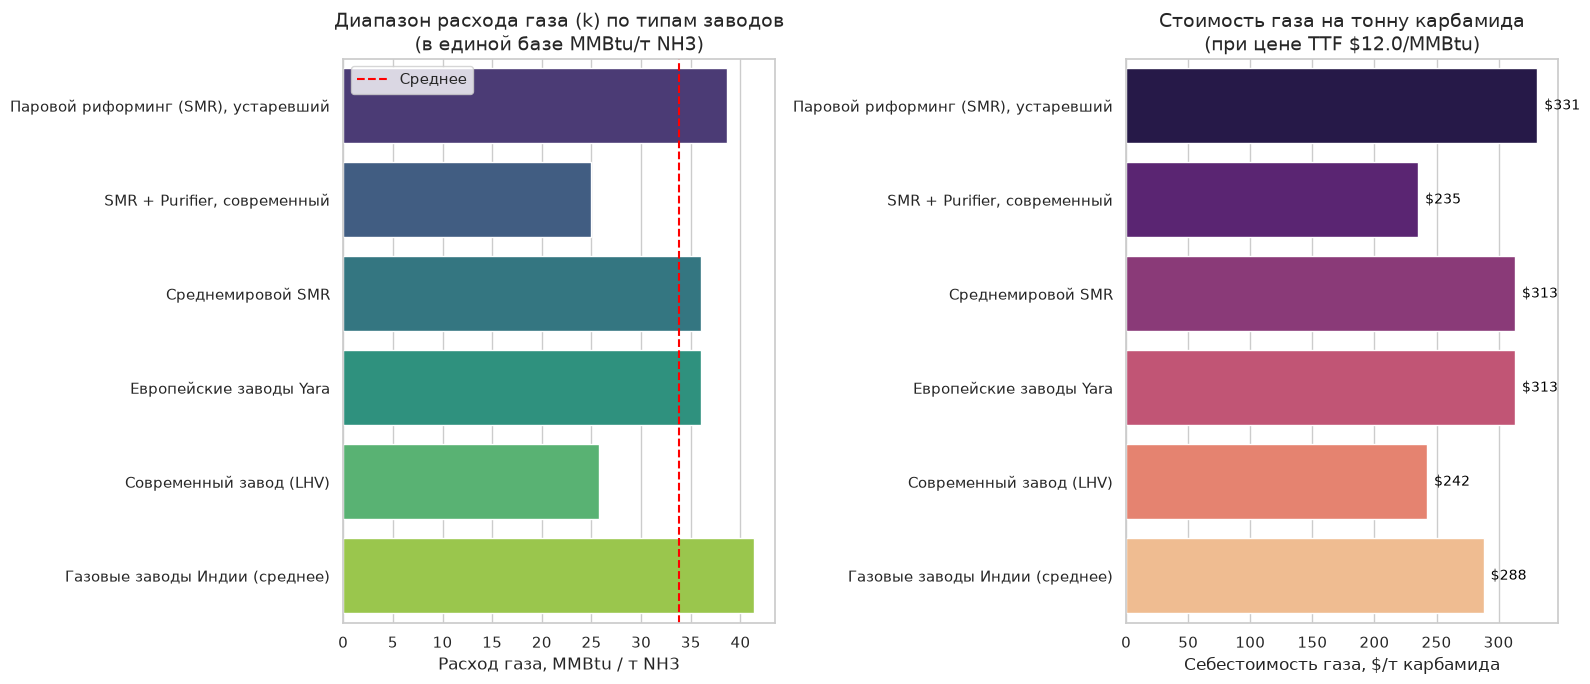

Разброс стоимости газа на тонну карбамида: $235 – $331
Экономический спред между лучшим и худшим заводом: $96 на тонну


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Настройка стиля
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# График 1: Диапазон k по типам заводов
sns.barplot(
    data=df_k, 
    y="Тип завода / Технология", 
    x="k_MMBtu_т_NH3", 
    palette="viridis", 
    ax=axes[0]
)
axes[0].set_title("Диапазон расхода газа (k) по типам заводов\n(в единой базе MMBtu/т NH3)", fontsize=14)
axes[0].set_xlabel("Расход газа, MMBtu / т NH3", fontsize=12)
axes[0].set_ylabel("")
axes[0].axvline(x=df_k["k_MMBtu_т_NH3"].mean(), color="red", linestyle="--", label="Среднее")
axes[0].legend()

# График 2: Экономический эффект при цене TTF $12/MMBtu
ttf_price = 12.0
df_k["gas_cost_usd_т_NH3"] = df_k["k_MMBtu_т_NH3"] * ttf_price
df_k["gas_cost_usd_т_карбамида"] = df_k["k_MMBtu_т_карбамида"] * ttf_price

sns.barplot(
    data=df_k, 
    y="Тип завода / Технология", 
    x="gas_cost_usd_т_карбамида", 
    palette="magma", 
    ax=axes[1]
)
axes[1].set_title(f"Стоимость газа на тонну карбамида\n(при цене TTF ${ttf_price}/MMBtu)", fontsize=14)
axes[1].set_xlabel("Себестоимость газа, $/т карбамида", fontsize=12)
axes[1].set_ylabel("")

# Добавляем значения на столбцы
for p in axes[1].patches:
    axes[1].annotate(f"${p.get_width():.0f}", 
                     (p.get_width(), p.get_y() + p.get_height() / 2), 
                     ha='left', va='center', fontsize=10, color='black', xytext=(5, 0), 
                     textcoords='offset points')

plt.tight_layout()
plt.savefig("k_economic_impact.png", dpi=300)
plt.show()

# Вывод разницы в деньгах
min_cost = df_k["gas_cost_usd_т_карбамида"].min()
max_cost = df_k["gas_cost_usd_т_карбамида"].max()
print(f"Разброс стоимости газа на тонну карбамида: ${min_cost:.0f} – ${max_cost:.0f}")
print(f"Экономический спред между лучшим и худшим заводом: ${max_cost - min_cost:.0f} на тонну")